# Лабораторная №3. Оптимизация гиперпараметров

Используем Titanic и дерево решений из лабораторной №2. Цель — `Survived`, основная метрика — F1 выживших (`1`). Baseline здесь — стартовая конфигурация дерева.

Сравниваем Grid Search и Random Search с одинаковым числом кандидатов и одинаковыми CV-разбиениями. Пространства заданы до запуска. Данные и разбиение взяты из лабы №2.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV, ParameterGrid, validation_curve,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
pd.set_option("display.precision", 4)
root = Path.cwd()
if not (root / "classification/data/titanic.csv").exists():
    root = root.parent
data = pd.read_csv(root / "classification/data/titanic.csv")
X = data.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])
y = data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2026
)
assert "Survived" not in X.columns
assert set(X_train.index).isdisjoint(X_test.index)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Признаки:", X.columns.tolist())

Train: (712, 7) Test: (179, 7)
Признаки: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


## 1. Исходная модель и кросс-валидация

Baseline — стартовое дерево из лабы №2 с глубиной 4, минимумом 3 объектов в листе, критерием Джини, `class_weight="balanced"` и `random_state=42`.

Числовые пропуски заполняем медианой, категориальные — самым частым значением. Категории кодируем One-Hot.

In [2]:
numeric = X.select_dtypes(include="number").columns.tolist()
categorical = X.select_dtypes(exclude="number").columns.tolist()
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical),
])
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=3, criterion="gini",
        class_weight="balanced", random_state=42,
    )),
])
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))
baseline_cv = cross_validate(
    baseline, X_train, y_train, cv=cv, scoring="f1", return_train_score=True
)
print("Исходный CV F1:", baseline_cv["test_score"].mean())
print("F1 по фолдам:", baseline_cv["test_score"])

Исходный CV F1: 0.7493238740591329
F1 по фолдам: [0.76923077 0.71153846 0.73267327 0.78899083 0.74418605]


## 2. Три гиперпараметра и пространства поиска

Grid Search полностью перебирает компактную сетку. Random Search выбирает 24 сочетания из более подробного пространства тех же трёх параметров.

У обоих по 24 кандидата × 5 фолдов = 120 CV-обучений и одно переобучение победителя. Время измеряем вместе с этим переобучением на одном процессе.

In [3]:
grid_space = {
    "model__max_depth": [2, 4, 12, None],
    "model__min_samples_leaf": [1, 5, 25],
    "model__criterion": ["gini", "entropy"],
}
random_space = {
    "model__max_depth": [2, 3, 4, 6, 8, 12, None],
    "model__min_samples_leaf": [1, 2, 3, 5, 10, 15, 25],
    "model__criterion": ["gini", "entropy"],
}
budget = len(ParameterGrid(grid_space))
print("Grid:", grid_space)
print("Random:", random_space)
print("Комбинаций Grid:", budget)
print("Комбинаций в пространстве Random:", len(ParameterGrid(random_space)))

Grid: {'model__max_depth': [2, 4, 12, None], 'model__min_samples_leaf': [1, 5, 25], 'model__criterion': ['gini', 'entropy']}
Random: {'model__max_depth': [2, 3, 4, 6, 8, 12, None], 'model__min_samples_leaf': [1, 2, 3, 5, 10, 15, 25], 'model__criterion': ['gini', 'entropy']}
Комбинаций Grid: 24
Комбинаций в пространстве Random: 98


## 3. Grid Search и Random Search



In [4]:
grid_search = GridSearchCV(
    clone(baseline), grid_space, scoring="f1", cv=cv,
    n_jobs=1, return_train_score=True, refit=True,
)
start = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start

random_search = RandomizedSearchCV(
    clone(baseline), random_space, n_iter=budget, scoring="f1", cv=cv,
    n_jobs=1, random_state=42, return_train_score=True, refit=True,
)
start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start

searches = {"Grid Search": grid_search, "Random Search": random_search}
search_results = pd.DataFrame([
    {"Метод": name,
     "Кандидатов": len(search.cv_results_["params"]),
     "CV-обучений": len(search.cv_results_["params"]) * len(cv),
     "CV F1": search.best_score_,
     "Время, с": seconds,
     "Параметры": search.best_params_}
    for (name, search), seconds in zip(searches.items(), [grid_seconds, random_seconds])
]).set_index("Метод")
display(search_results)
for name, search in searches.items():
    print(name, search.best_params_)

,Кандидатов,CV-обучений,CV F1,"Время, с",Параметры
Метод,,,,,
Grid Search,24,120,0.7621,0.9855,"{'model__criterion': 'gini', 'model__max_depth..."
Random Search,24,120,0.7542,1.0523,"{'model__min_samples_leaf': 2, 'model__max_dep..."


Grid Search {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 1}
Random Search {'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__criterion': 'gini'}


**Вывод.** Grid Search дал CV F1 = 0.7621, Random Search — 0.7542. У обоих 24 кандидата и 120 CV-обучений; время текущего запуска приведено в таблице. Лучший Grid: глубина 4, минимум 1 объект в листе, Джини. Лучший Random: глубина 4, минимум 2 объекта в листе, Джини.

Оба поиска улучшили CV F1 относительно стартовой конфигурации (0.7493). Grid показал больший прирост.

## 4. Влияние параметров на качество

Меняем один параметр, остальные оставляем как у исходного дерева. Показываем средний F1 обучения и валидации на пяти фолдах; полоса — ± одно стандартное отклонение validation F1.

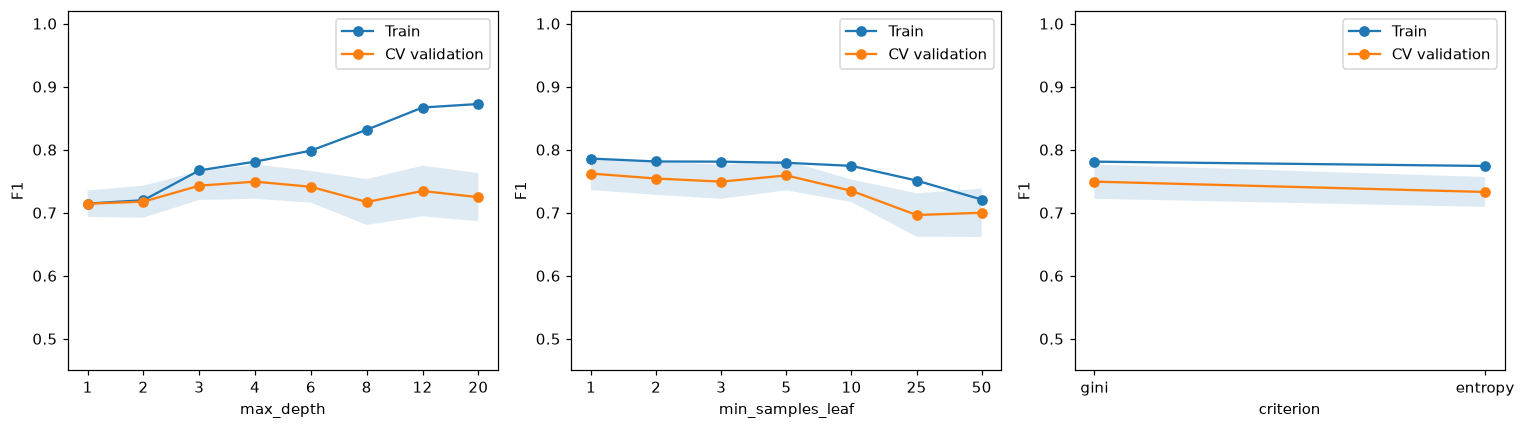

,Параметр,Значение,Train F1,CV F1
0,model__max_depth,1,0.7145,0.7143
1,model__max_depth,2,0.7198,0.7175
2,model__max_depth,3,0.7671,0.7429
3,model__max_depth,4,0.7810,0.7493
4,model__max_depth,6,0.7985,0.7411
5,model__max_depth,8,0.8316,0.7170
6,model__max_depth,12,0.8669,0.7345
7,model__max_depth,20,0.8725,0.7247
8,model__min_samples_leaf,1,0.7859,0.7621
9,model__min_samples_leaf,2,0.7813,0.7542


In [5]:
ranges = {
    "model__max_depth": [1, 2, 3, 4, 6, 8, 12, 20],
    "model__min_samples_leaf": [1, 2, 3, 5, 10, 25, 50],
    "model__criterion": ["gini", "entropy"],
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
curve_rows = []
for ax, (parameter, values) in zip(axes, ranges.items()):
    train_scores, val_scores = validation_curve(
        clone(baseline), X_train, y_train, param_name=parameter,
        param_range=values, scoring="f1", cv=cv, n_jobs=1,
    )
    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    positions = np.arange(len(values))
    ax.plot(positions, train_mean, "o-", label="Train")
    ax.plot(positions, val_mean, "o-", label="CV validation")
    ax.fill_between(positions, val_mean - val_std, val_mean + val_std, alpha=0.15)
    ax.set_xticks(positions, values)
    ax.set(xlabel=parameter.replace("model__", ""), ylabel="F1", ylim=(0.45, 1.02))
    ax.legend()
    for value, train, val in zip(values, train_mean, val_mean):
        curve_rows.append({"Параметр": parameter, "Значение": value, "Train F1": train, "CV F1": val})
plt.tight_layout()
plt.show()
display(pd.DataFrame(curve_rows))

## 5. Устойчивость и выбор финальной модели



,Исходная модель,Grid Search,Random Search
Fold 1,0.7692,0.7619,0.7692
Fold 2,0.7115,0.7238,0.7115
Fold 3,0.7327,0.7917,0.7573
Fold 4,0.7890,0.7890,0.7890
Fold 5,0.7442,0.7442,0.7442


,CV F1,CV std,Минимум,Максимум
Исходная модель,0.7493,0.0272,0.7115,0.7890
Grid Search,0.7621,0.0260,0.7238,0.7917
Random Search,0.7542,0.0259,0.7115,0.7890


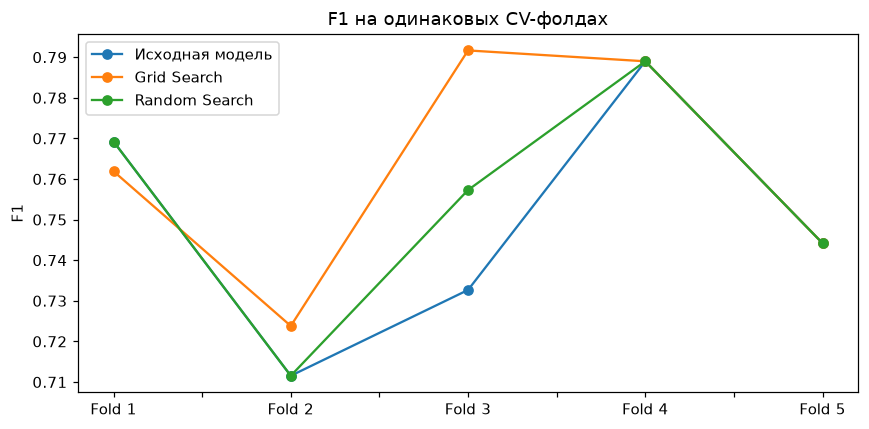

Выбрана по CV, до test: Grid Search


In [6]:
fold_scores = {"Исходная модель": baseline_cv["test_score"]}
for name, search in searches.items():
    fold_scores[name] = np.array([
        search.cv_results_[f"split{i}_test_score"][search.best_index_]
        for i in range(len(cv))
    ])
fold_table = pd.DataFrame(fold_scores, index=[f"Fold {i + 1}" for i in range(len(cv))])
display(fold_table)
stability = pd.DataFrame({
    name: {"CV F1": scores.mean(), "CV std": scores.std(),
           "Минимум": scores.min(), "Максимум": scores.max()}
    for name, scores in fold_scores.items()
}).T
display(stability)
fold_table.plot(marker="o", figsize=(8, 4), ylabel="F1", title="F1 на одинаковых CV-фолдах")
plt.tight_layout()
plt.show()

selected_name = stability["CV F1"].idxmax()
print("Выбрана по CV, до test:", selected_name)
baseline.fit(X_train, y_train)
final_models = {
    "Исходная модель": baseline,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_,
}
final_model = final_models[selected_name]

**Вывод по устойчивости.** Стандартное отклонение CV F1: исходное дерево — 0.0272, Grid — 0.0260, Random — 0.0259. Второй фолд труднее для всех трёх: вероятно, его пассажиры отличаются по составу

## 6. Финальная оценка на test

Все настройки зафиксированы. По максимальному CV F1 выбран Grid Search. Ниже один раз получаем test-прогноз для каждой из трёх конфигураций. 

In [7]:
rows = []
for name, model in final_models.items():
    prediction = model.predict(X_test)
    rows.append({
        "Модель": name,
        "CV F1": fold_scores[name].mean(),
        "CV std": fold_scores[name].std(),
        "Test F1": f1_score(y_test, prediction),
    })
results = pd.DataFrame(rows).set_index("Модель")
results["Изменение CV"] = results["CV F1"] - results.loc["Исходная модель", "CV F1"]
results["Изменение Test"] = results["Test F1"] - results.loc["Исходная модель", "Test F1"]
display(results)
print("Зафиксированная финальная модель:", selected_name)
print("Её Test F1:", results.loc[selected_name, "Test F1"])
print("Локальный ориентир F1 > 0.70:", results.loc[selected_name, "Test F1"] > 0.70)

,CV F1,CV std,Test F1,Изменение CV,Изменение Test
Модель,,,,,
Исходная модель,0.7493,0.0272,0.7355,0.0000,0.0000
Grid Search,0.7621,0.0260,0.7273,0.0128,-0.0082
Random Search,0.7542,0.0259,0.7355,0.0049,0.0000


Зафиксированная финальная модель: Grid Search
Её Test F1: 0.7272727272727273
Локальный ориентир F1 > 0.70: True


**Итог.** Относительно стартового дерева Grid Search поднял средний CV F1 с 0.7493 до 0.7621 (+0.0128), Random Search — до 0.7542 (+0.0049). На test исходное дерево и Random Search дали F1 = 0.7355, а Grid Search — 0.7273 (−0.0082 к исходному).

Прирост на CV не подтвердился на test. Возможные объяснения — различия в составе небольших выборок, более гибкие листья и оптимизм выбора максимума среди CV-кандидатов. 
